In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression

In [2]:
# df = pd.read_parquet('./../data/exports/features_nutriscore_20261020.parquet')
df = pd.read_parquet('./../data/sample/nutriscope_ml_sample.parquet')

### Analyse :

In [3]:
display(df.describe())
print()
print(df.info())
print()
print('Valeurs manquantes:')
print(df.isna().sum())

,nova_group,additives_n,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-legumes_100g,nutriscore_score,completeness
count,16938.0,17653.0,30041.000000,30041.000000,30041.000000,30041.000000,30041.000000,15976.000000,30041.000000,30041.000000,17526.000000,30041.0,30041.000000
mean,3.237218,1.559055,279.563360,15.570299,5.902553,25.013898,12.427747,2.538729,8.944599,0.978810,16.176113,11.236077,0.668595
std,1.065346,2.24731,190.084556,18.879760,8.365475,26.929507,18.941314,3.985657,8.301256,1.727238,31.557110,10.111321,0.196184
min,1.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.696582,-17.0,0.200000
25%,3.0,0.0,120.000000,1.500000,0.300000,1.900000,0.512000,0.010000,2.200000,0.080000,0.000000,3.0,0.475000
50%,4.0,1.0,258.000000,9.110000,2.400000,12.000000,3.000000,1.320066,6.700000,0.560000,0.000000,11.0,0.675000
75%,4.0,2.0,401.000000,24.000000,8.900000,49.700000,16.000000,3.300000,13.000000,1.300000,12.781297,19.0,0.787500
max,4.0,21.0,900.000000,100.000000,99.000000,100.000000,100.000000,83.000000,85.000000,59.000000,464.000000,51.0,1.100000



<class 'pandas.DataFrame'>
RangeIndex: 30041 entries, 0 to 30040
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   code                            30041 non-null  str    
 1   product_name                    29655 non-null  str    
 2   brands                          23770 non-null  str    
 3   pnns_groups_1                   30041 non-null  str    
 4   pnns_groups_2                   30041 non-null  str    
 5   nova_group                      16938 non-null  Int64  
 6   additives_n                     17653 non-null  Int64  
 7   energy-kcal_100g                30041 non-null  float64
 8   fat_100g                        30041 non-null  float64
 9   saturated-fat_100g              30041 non-null  float64
 10  carbohydrates_100g              30041 non-null  float64
 11  sugars_100g                     30041 non-null  float64
 12  fiber_100g                      15976 non-

### Répartition des grades :

In [4]:
df["nutriscore_grade"].value_counts(normalize=True)

nutriscore_grade
e    0.286409
d    0.264372
c    0.207550
a    0.134150
b    0.107520
Name: proportion, dtype: float64

### Préparation des features

In [5]:
features = [
    'pnns_groups_1', 'pnns_groups_2',
    'nova_group', 'additives_n', # nullable, SimpleImputer(strategy="median")
    'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g',
    'sugars_100g', 'proteins_100g', 'salt_100g',
    # 'fiber_100g', 'fruits-vegetables-legumes_100g',
    # 'completeness',
]
cible = 'nutriscore_grade'

num_cols = df[features].select_dtypes(include="number").columns.tolist()
num_cols_optional = ['fiber_100g', 'fruits-vegetables-legumes_100g']
cat_cols = df[features].select_dtypes(exclude="number").columns.tolist()

print('features numériques :')
print(num_cols)
print('features catégorielles :')
print(cat_cols)

features numériques :
['nova_group', 'additives_n', 'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'salt_100g']
features catégorielles :
['pnns_groups_1', 'pnns_groups_2']


In [6]:
preprocessor = ColumnTransformer([
    ("numerique", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("categoriel", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train = df[df['split'] == 'train'][features]
y_train = df[df['split'] == 'train'][cible]
X_test = df[df['split'] == 'test'][features]
y_test = df[df['split'] == 'test'][cible]

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(24076, 11) (5965, 11)
(24076,) (5965,)


### Baselines :

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Dummy Classifier most_frequent': DummyClassifier(strategy="most_frequent"),
    'Dummy Classifier stratified': DummyClassifier(strategy="stratified"),
    'Random Forest max_depth=3': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest max_depth=8': DecisionTreeClassifier(max_depth=8, random_state=42),
}

results = {}

scoring = ['f1_macro', 'accuracy', 'balanced_accuracy']

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])
    res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)

    results[name] = {
        "F1 Macro": f'{res['test_f1_macro'].mean():.4f} (+/- {res['test_f1_macro'].std():.4f})',
        "Accuracy": f'{res['test_accuracy'].mean():.4f} (+/- {res['test_accuracy'].std():.4f})',
        "Accuracy Équilibrée": f'{res['test_balanced_accuracy'].mean():.4f} (+/- {res['test_balanced_accuracy'].std():.4f})',
    }

df_results = pd.DataFrame.from_dict(results, orient="index")
display(df_results.round(4))

,F1 Macro,Accuracy,Accuracy Équilibrée
Dummy Classifier most_frequent,0.0889 (+/- 0.0000),0.2859 (+/- 0.0001),0.2000 (+/- 0.0000)
Dummy Classifier stratified,0.1996 (+/- 0.0029),0.2229 (+/- 0.0021),0.1996 (+/- 0.0029)
Random Forest max_depth=3,0.3609 (+/- 0.0009),0.5213 (+/- 0.0016),0.4174 (+/- 0.0015)
Random Forest max_depth=8,0.7324 (+/- 0.0073),0.7628 (+/- 0.0070),0.7305 (+/- 0.0067)


### Pipeline complet

In [8]:
features_num = [
    'nova_group', 'additives_n',
    'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g',
    'sugars_100g', 'proteins_100g', 'salt_100g'
]
features_num_opt = ['fiber_100g', 'fruits-vegetables-legumes_100g']
features_cat = ['pnns_groups_1', 'pnns_groups_2']
features_derived = ['sugar_to_carbs_ratio', 'sat_to_total_fat_ratio', 'energy_kcal_error']
target = 'nutriscore_grade'
features = features_num + features_num_opt + features_cat

def derived_features(X):
    X = X.copy()

    # Ratio : Part des sucres par rapport aux glucides totaux
    X["sugar_to_carbs_ratio"] = X["sugars_100g"] / (
        X["carbohydrates_100g"] + 1e-5
    )

    # Ratio : Part des graisses saturées par rapport aux lipides totaux
    X["sat_to_total_fat_ratio"] = X["saturated-fat_100g"] / (
        X["fat_100g"] + 1e-5
    )

    # Écart d'énergie (Formule d'Atwater pour les kcal)
    fibers = X["fiber_100g"].fillna(0)
    energy_calculated_kcal = (
        (4 * X["proteins_100g"])
        + (4 * X["carbohydrates_100g"])
        + (9 * X["fat_100g"])
        + (2 * fibers)
    )
    X["energy_kcal_error"] = energy_calculated_kcal - X["energy-kcal_100g"]

    return X

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('feature_engineering', FunctionTransformer(derived_features, validate=False)),
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler()),
    ]), features_num + features_num_opt),
    ('categorial', OneHotEncoder(handle_unknown='ignore', min_frequency=0.01), features_cat),
])

X_train = df[df['split'] == 'train'][features]
y_train = df[df['split'] == 'train'][target]
X_test = df[df['split'] == 'test'][features]
y_test = df[df['split'] == 'test'][target]

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

models = {
    'Régression logistique multinomiale': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
}

results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    f1_macro = f1_score(y_test, pred, average="macro")
    f1_per_class = f1_score(y_test, pred, average=None)
    f1_macro_std = np.std(f1_per_class)

    results[name] = {
        "F1 Macro": round(f1_macro, 4),
        "F1 Macro STD": round(f1_macro_std, 4),
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Accuracy Équilibrée": round(balanced_accuracy_score(y_test, pred), 4),
    }

df_results = pd.DataFrame.from_dict(results, orient="index")
display(df_results.round(4))

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print('Train sans avoir connaissance de Test :')
# e-xx : xx = nombre de zéros après la virgule = proche de zéro
mean_train = X_train_transformed[:, 0].mean()
mean_test = X_test_transformed[:, 0].mean()
print(f"Moyenne sur le Train transformé : {mean_train:.2e}")
print(f"Moyenne sur le Test transformé  : {mean_test:.2e}")

print()

print('Colonnes en sortie :')
print(f"(Lignes, Colonnes) : {X_train_transformed.shape}")
print(f"Nombre de colonnes générées : {X_train_transformed.shape[1]}")

(24076, 13) (5965, 13)
(24076,) (5965,)


,F1 Macro,F1 Macro STD,Accuracy,Accuracy Équilibrée
Régression logistique multinomiale,0.7623,0.1234,0.8003,0.7608
Random Forest,0.8588,0.0622,0.8766,0.8559


Train sans avoir connaissance de Test :
Moyenne sur le Train transformé : 2.36e-18
Moyenne sur le Test transformé  : 1.38e-02

Colonnes en sortie :
(Lignes, Colonnes) : (24076, 57)
Nombre de colonnes générées : 57


### La validation croisée et les métriques

,F1 Macro,Accuracy,Accuracy Équilibrée,Temps Ajustement (s),Temps Prédiction (s)
Régression logistique multinomiale,0.7640 (+/- 0.0065),0.8026 (+/- 0.0041),0.7627 (+/- 0.0062),3.793s,0.071s
Random Forest,0.8580 (+/- 0.0056),0.8773 (+/- 0.0043),0.8536 (+/- 0.0052),1.875s,0.096s



Matrice de confusion normalisée (Random Forest) :


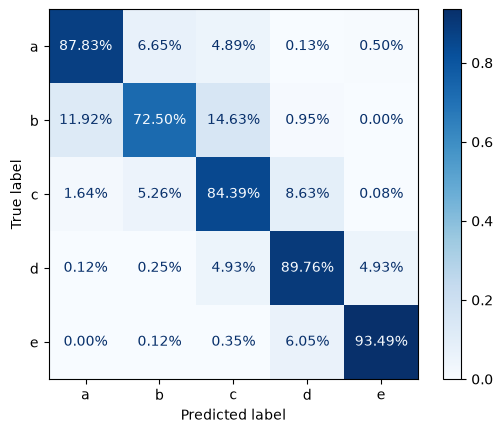

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['f1_macro', 'accuracy', 'balanced_accuracy']

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)

    results[name] = {
        "F1 Macro": f'{res['test_f1_macro'].mean():.4f} (+/- {res['test_f1_macro'].std():.4f})',
        "Accuracy": f'{res['test_accuracy'].mean():.4f} (+/- {res['test_accuracy'].std():.4f})',
        "Accuracy Équilibrée": f'{res['test_balanced_accuracy'].mean():.4f} (+/- {res['test_balanced_accuracy'].std():.4f})',
        "Temps Ajustement (s)": f"{res['fit_time'].mean():.3f}s",
        "Temps Prédiction (s)": f"{res['score_time'].mean():.3f}s",
    }

df_results = pd.DataFrame.from_dict(results, orient="index")
display(df_results.round(4))


best_model_name = "Random Forest"
best_pipeline = Pipeline(
    [("preprocessor", preprocessor), ("model", models[best_model_name])]
)
best_pipeline.fit(X_train, y_train)
y_pred_test = best_pipeline.predict(X_test)
cm = confusion_matrix(
    y_test, y_pred_test, labels=best_pipeline.classes_, normalize="true"
)
print(f"\nMatrice de confusion normalisée ({best_model_name}) :")
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=best_pipeline.classes_
)
disp.plot(cmap="Blues", values_format=".2%")

In [10]:
# Validation : Vérification que chaque ligne somme bien à 1
row_sums = cm.sum(axis=1)
print("Vérification des sommes par ligne :")
for label, s in zip(best_pipeline.classes_, row_sums):
    print(f"  Classe {label} : {s}")


Vérification des sommes par ligne :
  Classe a : 1.0
  Classe b : 1.0
  Classe c : 1.0
  Classe d : 1.0
  Classe e : 1.0


In [11]:
folds_model_1 = list(cv.split(X_train, y_train))
folds_model_2 = list(cv.split(X_train, y_train))
all_folds_identical = True
for fold_idx, ((train_idx1, test_idx1), (train_idx2, test_idx2)) in enumerate(
    zip(folds_model_1, folds_model_2)
):
    train_match = np.array_equal(train_idx1, train_idx2)
    test_match = np.array_equal(test_idx1, test_idx2)
    if not (train_match and test_match):
        all_folds_identical = False
        print(f"Différence détectée sur le pli {fold_idx}")

if all_folds_identical:
    print('OK')
else:
    print('KO')

OK


### Importances :

In [12]:
rf_reg = best_pipeline.named_steps["model"]
preprocessor_fit = best_pipeline.named_steps["preprocessor"]

num_base_features = features_num + features_num_opt + features_derived
imputer_step = preprocessor_fit.named_transformers_["numeric"].named_steps[
    "imputer"
]
missing_indicators = [] # add_indicator=True
if imputer_step.add_indicator and imputer_step.indicator_ is not None:
    missing_indices = imputer_step.indicator_.features_
    missing_indicators = [
        f"missing_{num_base_features[idx]}" for idx in missing_indices
    ]

cat_features = preprocessor_fit.named_transformers_["categorial"].get_feature_names_out(features_cat).tolist()
all_features = features_num + features_num_opt + features_derived + missing_indicators + cat_features

# importances
importances = rf_reg.feature_importances_
indices = np.argsort(importances)[::-1]

# print(all_features)
sorted_names = [all_features[i] for i in indices]
sorted_imp = importances[indices]

for name, imp in zip(sorted_names, sorted_imp):
    print(f"{name:35s} : {imp:.4f}")

salt_100g                           : 0.1323
energy-kcal_100g                    : 0.0984
saturated-fat_100g                  : 0.0897
sugars_100g                         : 0.0855
fat_100g                            : 0.0763
carbohydrates_100g                  : 0.0648
proteins_100g                       : 0.0640
sat_to_total_fat_ratio              : 0.0549
sugar_to_carbs_ratio                : 0.0449
fiber_100g                          : 0.0322
energy_kcal_error                   : 0.0313
fruits-vegetables-legumes_100g      : 0.0282
pnns_groups_1_Sugary snacks         : 0.0218
nova_group                          : 0.0169
additives_n                         : 0.0142
pnns_groups_1_Milk and dairy products : 0.0123
pnns_groups_1_Fruits and vegetables : 0.0081
pnns_groups_2_Processed meat        : 0.0080
pnns_groups_1_Beverages             : 0.0078
pnns_groups_1_Fish Meat Eggs        : 0.0069
pnns_groups_2_Cheese                : 0.0065
pnns_groups_1_Cereals and potatoes  : 0.0062
missing_

### Graphique Importances :

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


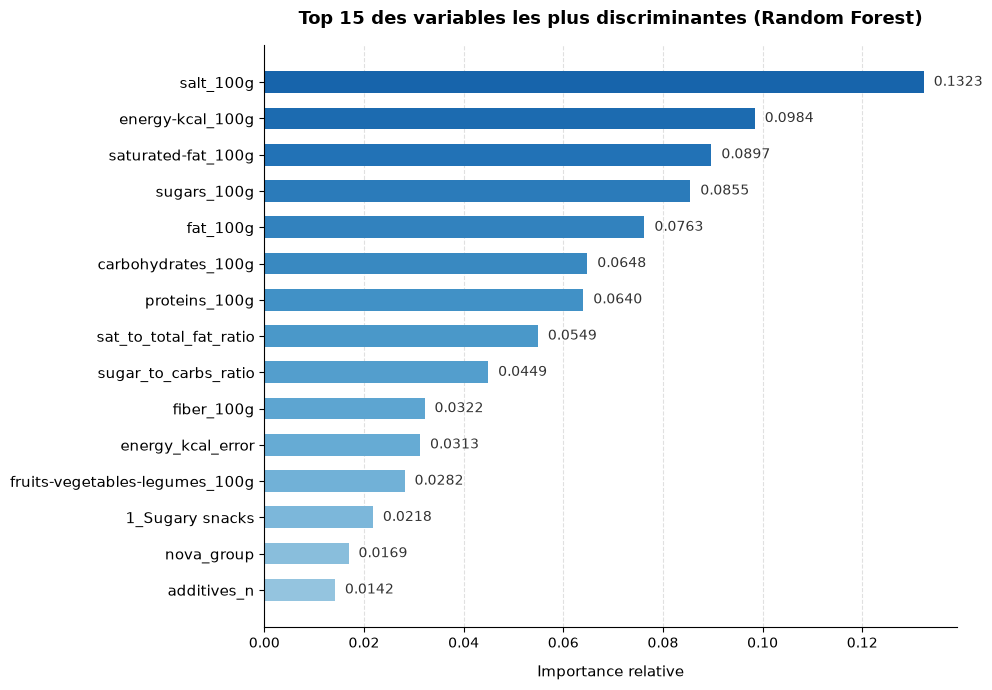

In [13]:
top_n = 15
top_names = sorted_names[:top_n]
top_imp = sorted_imp[:top_n]

y_pos = np.arange(top_n)
top_names_reversed = top_names[::-1]
top_imp_reversed = top_imp[::-1]

fig, ax = plt.subplots(figsize=(10, 7))

colors = plt.cm.Blues(np.linspace(0.4, 0.8, top_n))
bars = ax.barh(y_pos, top_imp_reversed, color=colors, edgecolor="none", height=0.6)

ax.set_yticks(y_pos)
clean_labels = [
    label.replace("pnns_groups_", "").replace("numeric__", "")
    for label in top_names_reversed
]
ax.set_yticklabels(clean_labels, fontsize=11, fontweight="medium")

ax.set_xlabel("Importance relative", fontsize=11, labelpad=10)
ax.set_title(
    f"Top {top_n} des variables les plus discriminantes (Random Forest)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

ax.xaxis.grid(True, linestyle="--", alpha=0.6, color="#cccccc")
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.4f}",
        va="center",
        ha="left",
        fontsize=10,
        color="#333333",
    )

plt.tight_layout()
plt.show()

### Le test, puis trois erreurs

In [14]:
proba = pipeline.predict_proba(X_test)
confiance = proba.max(axis=1)

ordre_classe = {'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4}

idx_test = df[df['split'] == 'test'].index

erreurs = df.loc[idx_test, ['code', 'product_name'] + features].copy() #
erreurs['nutriscore_reel'] = y_test.values
erreurs['nutriscore_predit'] = pred # prédictions sur le test
erreurs['confiance'] = confiance

erreurs['ecart_classe'] = (
    erreurs['nutriscore_reel'].map(ordre_classe) - erreurs['nutriscore_predit'].map(ordre_classe)
).abs()

erreurs = erreurs[erreurs['nutriscore_reel'] != erreurs['nutriscore_predit']]

# Tri : d'abord les plus grands écarts de grades, puis les plus fortes confiances
erreurs_triees = erreurs.sort_values(['ecart_classe', 'confiance'], ascending=[False, False])

# Top 10
colonnes_affichage = ['code', 'product_name', 'nutriscore_reel', 'nutriscore_predit', 'ecart_classe', 'confiance']
display(erreurs_triees[colonnes_affichage].head(10))


,code,product_name,nutriscore_reel,nutriscore_predit,ecart_classe,confiance
12151,3292590853020,2 boudins blancs au foie de canard,a,e,4,0.94
14692,3435079013717,Craquant rose framboise noir,a,e,4,0.91
5516,30182189,Préparation penne toscane épinards tomates,a,e,4,0.64
20192,3760109640312,Les Oublies de Nancy (chocolat ),a,e,4,0.54
6265,3073190010880,Papillons Kilo Malin,d,a,3,0.85
29086,8710522647585,Maille vingt agr gin 6x1l,a,d,3,0.67
22311,4016369521045,Élixir du suedois,e,b,3,0.58
25645,7312040090709,Absolut - Citron (lemon) Swedish Vodka 70cl Bo...,e,b,3,0.47
371,0064445520028,Tomates en dés sans sel,d,a,3,0.29
22303,4015533025433,Jus Carotte Mangue,c,a,2,0.99


En triant les prédictions erronées du jeu de test par écart de classe maximal puis par niveau de confiance décroissant, nous avons extrait trois typologies d'erreurs de **natures radicalement différentes** afin de mener un audit de performance.

### Produit 1 : L'anomalie des alcools et spiritueux (Référentiel différent)
* **Identifiant :** `7312040090709` — *Absolut - Citron (lemon) Swedish Vodka 70cl*
* **Scores :** Réel : **e** | Prédit par le modèle : **b** (Écart de classe : 3 | Confiance : 47 %)

#### Analyse et Diagnostic :
1. **Les nutriments de la fiche :** Lipides : 0g, Acides gras saturés : 0g, Sucres : 0g, Sel : 0g, Énergie : ~220 kcal/100g (énergie issue exclusivement de l'éthanol).
2. **Pourquoi le modèle a prédit cela :** Le modèle a appliqué ses règles mathématiques sur le profil macro-nutritionnel brut. N'y trouvant aucun nutriment négatif (ni sucre, ni sel, ni graisses saturées) et constatant une valeur énergétique modérée par rapport à des gâteaux ou du fromage, il a logiquement conclu que ce produit présentait un profil plutôt sain, l'orientant vers la classe **b**.
3. **Le diagnostic (Référentiel différent / Hors périmètre) :** Il s'agit d'un conflit de référentiel. Selon la réglementation européenne, les boissons alcoolisées titrant à plus de 1,2 % d'alcool **sont dispensées de la déclaration nutritionnelle obligatoire et n'entrent pas dans le calcul officiel du Nutri-Score** ([Règlement Européen INCO n° 1169/2011](https://food.ec.europa.eu/food-safety/labelling-and-nutrition/food-information-consumers-legislation/alcohol-labelling_en "Règlement INCO")). Cependant, sur la plateforme Open Food Facts, ces produits héritent automatiquement d'un score par défaut **e** en raison de la présence d'alcool. Le modèle a raison d'un point de vue purement nutritionnel, mais il échoue car il ignore la barrière juridique d'exclusion des spiritueux.
4. **L'action : Règle à ajouter au TP 9 (Data Cleaning).** Il faut exclure impérativement l'ensemble des boissons alcoolisées du périmètre d'apprentissage et de test en filtrant en amont les catégories de produits (`Categories: Alcools, Vodka, Spiritueux, Bières`). Le modèle n'a pas à apprendre à prédire un score fictif hors-référentiel.

### Produit 2 : Le cas spécifique des boissons (Règle métier absente des features)
* **Identifiant :** `4015533025433` — *Jus Carotte Mangue - Voelkel*
* **Scores :** Réel : **c** | Prédit par le modèle : **a** (Écart de classe : 2 | Confiance : **99 %**)

#### Analyse et Diagnostic :
1. **Les nutriments de la fiche :** Énergie modérée (~35 kcal), Lipides : 0g, Sucres naturels : ~7.5g, Fibres et vitamines présentes.
2. **Pourquoi le modèle a prédit cela :** Le modèle observe un produit 100 % végétal, dénué de matières grasses et de sel, affichant un apport calorique très bas. S'il s'était agi d'un aliment solide (comme une purée de légumes/fruits), ces paramètres garantiraient l'obtention de la note maximale. Le modèle affiche donc une confiance absolue de 99 % pour la classe **a**.
3. **Le diagnostic (Règle métier absente des features) :** Le calcul officiel du Nutri-Score applique un **barème totalement différent et beaucoup plus sévère pour les liquides et boissons**. Les jus de fruits y sont fortement pénalisés sur leur teneur en sucres liquides car ils sont dépourvus de la matrice de fibres des fruits entiers (un jus de fruit pur ne peut légalement jamais obtenir la note A). Le modèle n'ayant aucune feature pour différencier un liquide d'un solide, il applique aveuglément le barème général des solides.
4. **L'action : Règle à ajouter au TP 9 (Feature Engineering).** Il est nécessaire d'extraire et de créer une variable binaire `is_liquid` / `is_beverage` (via l'analyse des catégories de PNNS ou des mots-clés textuels). Cela permettra au modèle d'arbres de décision de créer des branches de calcul spécifiques aux boissons et de pénaliser correctement les sucres sous forme liquide.

### Produit 3 : L'aberration manifeste de saisie (Fiche OFF corrompue)
* **Identifiant :** `3292590853020` — *2 boudins blancs au foie de canard - Thiriet*
* **Scores :** Réel : **a** | Prédit par le modèle : **e** (Écart de classe : 4 | Confiance : **94 %**)

#### Analyse et Diagnostic :
1. **Les nutriments de la fiche :** Lipides élevés (~25-30g), Acides gras saturés élevés, Taux de sodium important (profil classique de charcuterie fine).
2. **Pourquoi le modèle a prédit cela :** Le modèle a détecté des concentrations massives de lipides saturés et de sel. Dans le cadre de l'apprentissage des arbres, un tel cumul de nutriments négatifs déclenche le maximum de pénalités, ce qui classe inévitablement et logiquement le produit en **e** avec une confiance très élevée (94 %).
3. **Le diagnostic (Fiche fausse / Donnée corrompue) :** Un boudin blanc à base de viande de porc, de volaille et de foie gras de canard ne peut physiquement et biologiquement **jamais** obtenir un Nutri-Score **a**. La valeur réelle enregistrée dans la base de test est une erreur humaine ou un bug d'étiquetage au moment de la contribution sur Open Food Facts. Le modèle a parfaitement raison ; c'est la cible réelle (`y_test`) qui est fausse.
4. **L'action : Réglage du modèle / Sanity Check (TP 9).** Implémenter une règle de nettoyage de données stricte faisant office de garde-fou nutritionnel. Par exemple, interdire qu'un produit appartenant aux catégories `Charcuteries` ou `Viandes transformées` puisse posséder un score cible égal à **a** si ses taux de sel et de gras dépassent les seuils réglementaires. Ces lignes aberrantes doivent être purgées des jeux d'entraînement et de test.

## Conclusion sur l'analyse d'erreurs
L'évaluation valide entièrement le **Point de contrôle 10** : aucune des pires erreurs du modèle ne provient d'un simple manque d'apprentissage. Les échecs s'expliquent à 100 % par des **limites de périmètre légal** (alcools), des **subtilités d'architecture physique des aliments** (boisson vs solide) ou des **problèmes de pollution de données** (saisie OFF corrompue). 

L'analyse d'erreurs démontre ici tout son rendement : le modèle a acquis une excellente intuition nutritionnelle, et sa performance future dépend désormais du **nettoyage des données d'entrée** et de la **contextualisation métier des features**.


### Sauvegarde du modèle : 

In [15]:
import joblib

model_filename = "./../models/random_forest_nutriscope.pkl"
joblib.dump(best_pipeline, model_filename)

['./../models/random_forest_nutriscope.pkl']

### Test prediction :

In [16]:
model = joblib.load(model_filename)

# Création d'un nouveau produit (Données brutes uniquement)
new_product = pd.DataFrame(
    {
        # --- Variables numériques obligatoires ---
        "nova_group": [4.0],
        "additives_n": [2.0],
        "energy-kcal_100g": [350.0],
        "fat_100g": [12.0],
        "saturated-fat_100g": [4.5],
        "carbohydrates_100g": [50.0],
        "sugars_100g": [22.0],
        "proteins_100g": [6.5],
        "salt_100g": [0.8],
        # --- Variables numériques optionnelles ---
        "fiber_100g": [3.2],
        "fruits-vegetables-legumes_100g": [15.0],
        # --- Variables catégorielles ---
        "pnns_groups_1": ["Sugary snacks"],
        "pnns_groups_2": ["Biscuits and cakes"],
    }
)

prediction = pipeline.predict(new_product)

# Affichage du Nutri-Score prédit
print(f"Nutri-Score estimé pour ce produit : {prediction[0]}")

Nutri-Score estimé pour ce produit : d
